In [21]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from scipy.interpolate import interp1d

# 1. Configurar a grade temporal contínua
# Simulamos um cenário ideal: um telescópio observando diariamente por 10 anos.
dt = 1.0  # Resolução de 1 dia
t_ideal = np.arange(0, 3650, dt) # 3650 dias = 10 anos
N_ideal = len(t_ideal)

In [22]:
# Gerando a Curva de Luz Contínua (Ruído Vermelho)
# AGNs possuem uma "memória temporal" (ruído vermelho). 
# Construímos o sinal no domínio da frequência e depois aplicamos a IFFT.

# Fixando a semente para garantir reprodutibilidade nos testes
np.random.seed(42)

# Criando as frequências (metade positiva do espectro de Fourier)
freqs_ideal = np.fft.fftfreq(N_ideal, d=dt)[1:N_ideal//2]

# Definindo o PSD teórico do AGN (Lei de potência com declive 1.5)
psd_teorico = 1.0 / (freqs_ideal**1.5) 

# Sorteando fases aleatórias (entre 0 e 2*pi) para que o sinal seja estocástico
fase = np.random.uniform(0, 2*np.pi, len(freqs_ideal))

# Construindo o espectro complexo (Amplitude + Fase) e espelhando para a IFFT
espectro_complexo = np.sqrt(psd_teorico) * np.exp(1j * fase)
espectro_completo = np.concatenate(([0], espectro_complexo, np.zeros(N_ideal//2)))

# Transformada Inversa: resulta na curva de luz perfeita, contínua no tempo
sinal_ideal = np.real(np.fft.ifft(espectro_completo))


In [23]:

# Aplicando a Janela de Observação (Criando Gaps)
# Simulamos a obstrução pelo Sol: o quasar fica invisível em parte do ano.

t_obs = []

# Criamos uma máscara booleana: True para dias observados, False para os gaps
dias_do_ano = t_ideal % 365.25
mascara_observacao = ~((dias_do_ano > 100) & (dias_do_ano < 250))

# Filtramos os arrays de tempo e de fluxo diretamente, sem interpolação
t_obs = t_ideal[mascara_observacao]
y_obs = sinal_ideal[mascara_observacao]

# Adicionamos o ruído branco do instrumento
y_obs += np.random.normal(0, 0.1, size=len(y_obs))

In [24]:



# Calculando o Periodograma de Lomb-Scargle
# Agora aplicamos o método estatístico para tentar recuperar o PSD 
# a partir dos dados esburacados (t_obs e y_obs).

# Criando grade de frequências de teste em escala logarítmica (10^-4 a 10^-1)
freq_lsp = np.logspace(-4, -1, 1000) 

# Calculando a potência espectral bruta via Lomb-Scargle
power_lsp = LombScargle(t_obs, y_obs).power(freq_lsp)


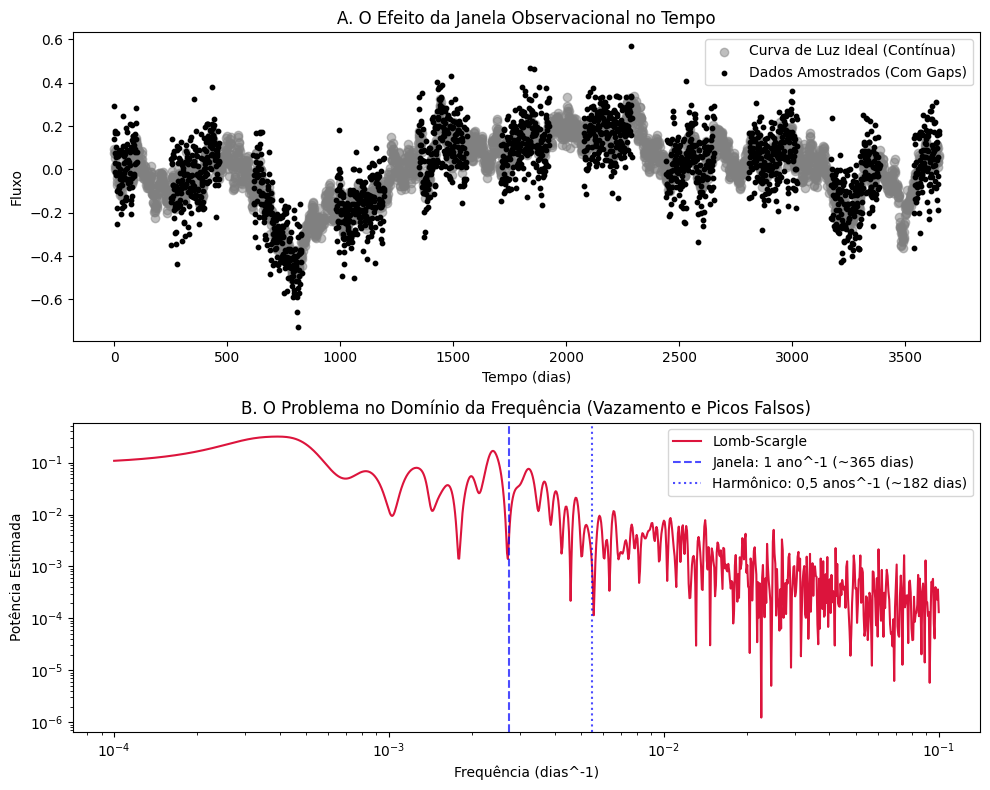

In [25]:


# Plotagem e Identificação do Aliasing
# Comparamos o sinal no tempo com o espectro sujo na frequência,
# marcando onde os artefatos terrestres da nossa janela vão aparecer.

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# --- Painel A: Domínio do Tempo ---
axes[0].scatter(t_ideal, sinal_ideal, color='gray', alpha=0.5, label='Curva de Luz Ideal (Contínua)')
axes[0].scatter(t_obs, y_obs, color='black', s=10, label='Dados Amostrados (Com Gaps)')
axes[0].set_title('A. O Efeito da Janela Observacional no Tempo')
axes[0].set_xlabel('Tempo (dias)')
axes[0].set_ylabel('Fluxo')
axes[0].legend(loc='upper right')

# --- Painel B: Domínio da Frequência ---
axes[1].loglog(freq_lsp, power_lsp, color='crimson', lw=1.5, label='Lomb-Scargle')

# Frequência fundamental da interrupção (1 volta por ano ao redor do Sol)
f_ano = 1.0 / 365.25

# Marcação do artefato de 1 ano (Frequência Fundamental)
axes[1].axvline(f_ano, color='blue', linestyle='--', alpha=0.7, 
                label='Janela: 1 ano^-1 (~365 dias)')

# Marcação do artefato de 6 meses (Primeiro Harmônico, o dobro da frequência, à direita)
axes[1].axvline(2 * f_ano, color='blue', linestyle=':', alpha=0.7, 
                label='Harmônico: 0,5 anos^-1 (~182 dias)')

axes[1].set_title('B. O Problema no Domínio da Frequência (Vazamento e Picos Falsos)')
axes[1].set_xlabel('Frequência (dias^-1)')
axes[1].set_ylabel('Potência Estimada')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('analise_psd_gaps.png', dpi=300)
plt.show()